# 3. Exploratory Data Analysis

**Input:** the three clean tables from notebook 2 (`data/clean/`).
**Output:** figures in `reports/figures/`, and the EDA findings → decisions table at the end, which notebook 4 implements.

**Question:** given the patient, the report and the suspect drugs, will a case involve hospitalization or death
(`y_hosp_or_death`)? This notebook looks at what drives that target and what must be kept out of the model (leakage).

| Section | What it answers |
|---|---|
| 2 | The target: rate over time, who has an unknown target |
| 3 | Patients: age, sex, weight, missingness |
| 4 | Drugs: top ingredients, litigation-driven drugs, polypharmacy, how many drugs to encode |
| 5 | Reactions, and why they leak the target |
| 6 | Reporters, report type, geography, legacy and mass reports |

Population, split, features, scaling and the baseline model are in **notebook 4**.

## 1. Setup and load

The case table is ~8.5M rows but under 1 GB in memory. The long tables (14M ingredient rows, 25M reaction rows)
are loaded with their text columns as categoricals, which keeps them small.

In [1]:
from __future__ import annotations

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq

try:
    from IPython.display import display
except ImportError:
    def display(obj):
        print(obj)

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
plt.rcParams["figure.dpi"] = 110

CLEAN_DIR = PROJECT_ROOT / "data" / "clean"
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

reports = pd.read_parquet(CLEAN_DIR / "reports_clean.parquet")
print(f"reports: {reports.shape[0]:,} rows x {reports.shape[1]} cols, "
      f"{reports.memory_usage(deep=True).sum() / 1e9:.2f} GB")

TARGET = "y_hosp_or_death"
# float copy of the target: 1.0 / 0.0 / NaN, so .mean() gives the positive rate among known cases
reports["y"] = reports[TARGET].astype("float32")
BASE_RATE = reports["y"].mean()
print(f"known target: {reports['y'].notna().mean():.1%} of cases; base positive rate {BASE_RATE:.1%}")


def load_long(name: str, text_col: str, extra_cols: tuple[str, ...] = ()) -> pd.DataFrame:
    """Load a long table with its text column as a categorical, and attach the case target."""
    cols = ["safetyreportid", text_col, *extra_cols]
    df = pq.read_table(CLEAN_DIR / name, columns=cols, read_dictionary=[text_col]).to_pandas()  # folder of part files
    df["y"] = df["safetyreportid"].map(reports.set_index("safetyreportid")["y"]).astype("float32")
    return df


def rate_table(df: pd.DataFrame, by, min_n: int = 0) -> pd.DataFrame:
    """Cases, known-target cases, positive rate and lift over the base rate, per group."""
    out = df.groupby(by, observed=True, dropna=False)["y"].agg(n_cases="size", n_known="count", positive_rate="mean")
    out["lift"] = out["positive_rate"] / BASE_RATE
    return out[out["n_known"] >= min_n]


def save_fig(fig, name: str) -> None:
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

reports: 8,477,316 rows x 23 cols, 0.84 GB
known target: 98.9% of cases; base positive rate 26.1%


# Part A — EDA

## 2. The target

1. What share of cases end in hospitalization or death, and is that stable over quarters?
2. Who has an **unknown** target? If unknowns concentrate in one group, dropping them biases the model.
3. Death vs. hospitalization: one target or two?

quarter,2020Q1,2020Q2,2020Q3,2020Q4,2021Q1,2021Q2,2021Q3,2021Q4,2022Q1,2022Q2,2022Q3,2022Q4,2023Q1,2023Q2,2023Q4,2024Q2,2024Q3,2025Q1,2025Q2,2025Q3,2025Q4,2026Q1,2026Q2
n_cases,381618.000,349430.000,349261.000,347596.000,381315.000,397065.000,423247.000,362744.000,390389.000,356299.000,381736.000,404303.000,366817.000,368197.00,367407.000,333629.000,359440.000,321343.000,322905.000,387495.000,341639.000,365832.000,417609.000
positive_rate,0.287,0.273,0.307,0.307,0.264,0.229,0.227,0.264,0.250,0.242,0.243,0.239,0.264,0.26,0.275,0.267,0.250,0.263,0.258,0.270,0.268,0.260,0.247
unknown_share,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.025,0.021,0.017,0.015,0.014,0.018,0.02,0.018,0.010,0.018,0.018,0.016,0.012,0.038,0.009,0.000


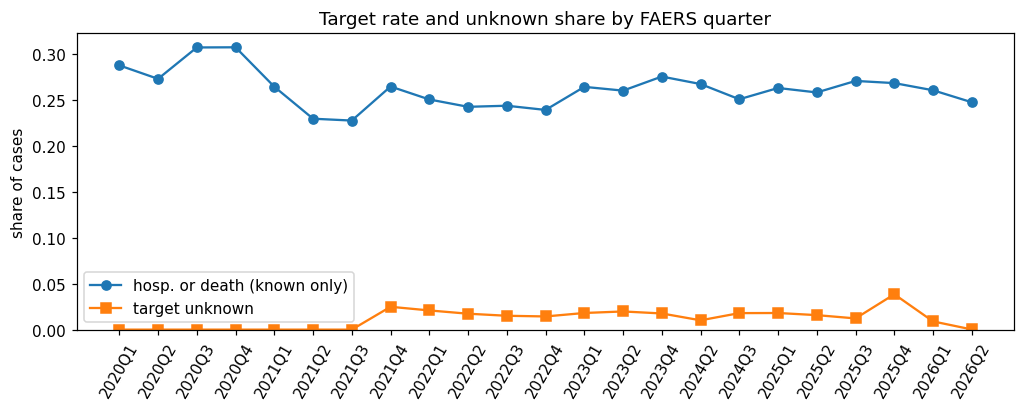

unknown target by reporter:


reporter,lawyer,consumer,NaN,pharmacist,physician,other_hcp
share_unknown,0.003,0.007,0.008,0.015,0.016,0.018


death vs. hospitalization (known cases):


hospitalization,False,True,All
death,,,
False,6194405,1412535,7606940
True,547807,143403,691210
All,6742212,1555938,8298150


In [2]:
by_quarter = rate_table(reports, "quarter")
by_quarter["unknown_share"] = 1 - by_quarter["n_known"] / by_quarter["n_cases"]
display(by_quarter[["n_cases", "positive_rate", "unknown_share"]].round(3).T)

fig, ax = plt.subplots(figsize=(11, 3.5))
x = by_quarter.index.astype(str)
ax.plot(x, by_quarter["positive_rate"], marker="o", label="hosp. or death (known only)")
ax.plot(x, by_quarter["unknown_share"], marker="s", label="target unknown")
ax.set_ylim(0, None)
ax.set_ylabel("share of cases")
ax.set_title("Target rate and unknown share by FAERS quarter")
ax.tick_params(axis="x", rotation=60)
ax.legend()
save_fig(fig, "target_by_quarter")
plt.show()

print("unknown target by reporter:")
display(reports.assign(unknown=reports["y"].isna()).groupby("reporter", observed=True, dropna=False)["unknown"]
        .mean().sort_values().rename("share_unknown").to_frame().T.round(3))

print("death vs. hospitalization (known cases):")
display(pd.crosstab(reports["death"], reports["hospitalization"], margins=True))

## 3. Patients

- Target rate by age group and sex.
- Is **missingness itself** predictive? If a missing age or sex has its own target rate, the model needs
  missing-indicator features, not just imputation.
- Is weight worth keeping with ~83% missing?

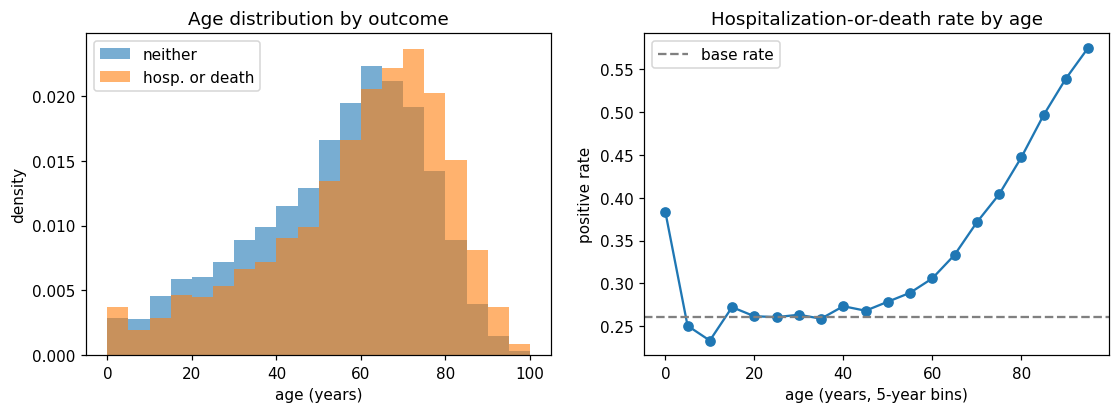

by age group (incl. missing):


,n_cases,n_known,positive_rate,lift
age_group,,,,
adolescent,160928,158768,0.249,0.955
adult,2931004,2888086,0.268,1.026
child,149826,147585,0.252,0.965
elderly,1971602,1945403,0.388,1.488
infant,34871,34122,0.401,1.536
missing,3201139,3178796,0.175,0.672
neonate,27946,27399,0.368,1.412


by sex (incl. missing):


,n_cases,n_known,positive_rate,lift
sex,,,,
female,4226218,4176971,0.240,0.922
male,2941997,2905874,0.322,1.235
missing,1309101,1297314,0.190,0.727


does missingness carry signal?


,present,missing,share_missing
age_years,0.323,0.18,0.436
sex,0.274,0.19,0.154
weight_kg,0.369,0.24,0.835


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
known_age = reports.loc[reports["y"].notna() & reports["age_years"].notna(), ["age_years", "y"]]
bins = np.arange(0, 105, 5)
for label, part in known_age.groupby("y"):
    axes[0].hist(part["age_years"], bins=bins, alpha=0.6, density=True,
                 label="hosp. or death" if label == 1 else "neither")
axes[0].set_xlabel("age (years)")
axes[0].set_ylabel("density")
axes[0].set_title("Age distribution by outcome")
axes[0].legend()

age_rate = known_age.groupby(pd.cut(known_age["age_years"], bins, right=False), observed=True)["y"].mean()
axes[1].plot([b.left for b in age_rate.index], age_rate.values, marker="o")
axes[1].axhline(BASE_RATE, color="grey", ls="--", label="base rate")
axes[1].set_xlabel("age (years, 5-year bins)")
axes[1].set_ylabel("positive rate")
axes[1].set_title("Hospitalization-or-death rate by age")
axes[1].legend()
save_fig(fig, "age_vs_target")
plt.show()

print("by age group (incl. missing):")
display(rate_table(reports.assign(age_group=reports["age_group"].astype("string").fillna("missing")), "age_group").round(3))
print("by sex (incl. missing):")
display(rate_table(reports.assign(sex=reports["sex"].astype("string").fillna("missing")), "sex").round(3))

print("does missingness carry signal?")
miss = pd.DataFrame({
    col: reports.groupby(reports[col].isna())["y"].mean()
    for col in ["age_years", "sex", "weight_kg"]
}).rename(index={False: "present", True: "missing"}).T
miss["share_missing"] = [reports[c].isna().mean() for c in miss.index]
display(miss.round(3))

## 4. Drugs

- Top suspect ingredients, and how much of each is **mass** or **lawyer** reports.
- Which ingredients have a high or low target rate (min 1,000 known cases, so small counts don't mislead)?
- Polypharmacy: target rate vs. number of drugs.
- How many ingredients cover 80% / 95% of mentions? This sets K for top-K drug features.

In [4]:
ingredients = load_long("case_ingredients", "ingredient")
flags = reports.set_index("safetyreportid")[["is_mass_report", "reporter"]]
ingredients = ingredients.join(flags, on="safetyreportid")
print(f"ingredients: {len(ingredients):,} rows, {ingredients['ingredient'].nunique():,} distinct, "
      f"{ingredients.memory_usage(deep=True).sum() / 1e9:.2f} GB")

top = rate_table(ingredients, "ingredient").sort_values("n_cases", ascending=False).head(25)
top["share_mass"] = ingredients[ingredients["ingredient"].isin(top.index)].groupby("ingredient", observed=True)["is_mass_report"].mean()
top["share_lawyer"] = (ingredients[ingredients["ingredient"].isin(top.index)]
                       .assign(lawyer=lambda d: d["reporter"].eq("lawyer"))
                       .groupby("ingredient", observed=True)["lawyer"].mean())
print("top 25 suspect ingredients:")
display(top.round(3))

drug_rates = rate_table(ingredients, "ingredient", min_n=1000)
print(f"\n{len(drug_rates):,} ingredients with >= 1,000 known cases")
print("highest target rate:")
display(drug_rates.sort_values("positive_rate", ascending=False).head(15).round(3))
print("lowest target rate:")
display(drug_rates.sort_values("positive_rate").head(15).round(3))

ingredients: 14,011,496 rows, 7,183 distinct, 0.24 GB


top 25 suspect ingredients:


,n_cases,n_known,positive_rate,lift,share_mass,share_lawyer
ingredient,,,,,,
RANITIDINE,402279,401825,0.074,0.285,0.202,0.468
DUPILUMAB,400804,400732,0.050,0.193,0.001,0.000
ADALIMUMAB,236901,235004,0.240,0.920,0.0,0.000
LENALIDOMIDE,202669,197452,0.281,1.076,0.001,0.000
ACETAMINOPHEN,184841,183418,0.348,1.332,0.0,0.213
OXYCODONE,164265,163603,0.240,0.921,0.0,0.469
METHOTREXATE,136861,133868,0.362,1.388,0.0,0.001
TIRZEPATIDE,131757,131733,0.066,0.252,0.042,0.006
RITUXIMAB,115061,111052,0.436,1.670,0.0,0.000



1,123 ingredients with >= 1,000 known cases
highest target rate:


,n_cases,n_known,positive_rate,lift
ingredient,,,,
CALCIUM ASCORBATE,1039,1036,0.900,3.449
FLUMETHASONE,1297,1295,0.879,3.369
FLUMETHASONE PIVALATE,2921,2912,0.877,3.361
EPCORITAMAB,1794,1786,0.876,3.360
CALCIUM GLUBIONATE,2190,2183,0.869,3.332
INVESTIGATIONAL PRODUCT,1560,1539,0.832,3.191
ILOPROST,1333,1321,0.820,3.143
TORSEMIDE,5466,5421,0.807,3.095
ALCOHOL,13087,13026,0.801,3.072


lowest target rate:


,n_cases,n_known,positive_rate,lift
ingredient,,,,
ADAPALENE,99264,99261,0.000,0.001
OCTOCRYLENE,71138,71108,0.002,0.006
AVOBENZONE,71186,71153,0.002,0.006
OCTISALATE,71177,71151,0.002,0.006
COLLAGENASE CLOSTRIDIUM HISTOLYTICUM-AAES,1162,1162,0.003,0.010
NORELGESTROMIN,4333,4330,0.004,0.016
PRABOTULINUMTOXINA-XVFS,2291,2287,0.007,0.027
ACOLTREMON,4212,4208,0.009,0.034
DOCOSANOL,2389,2376,0.009,0.034


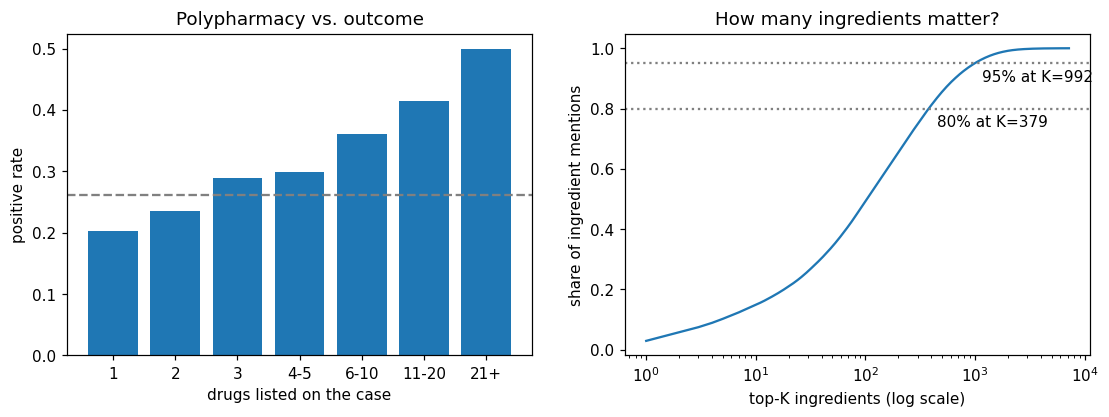

drugs,1,2,3,4-5,6-10,11-20,21+
n_cases,3885098.000,1444090.000,729384.000,860751.000,865387.000,509566.000,183040.000
n_known,3849691.000,1426982.000,719161.000,848580.000,852456.000,502636.000,180653.000
positive_rate,0.203,0.236,0.289,0.298,0.361,0.415,0.499
lift,0.778,0.904,1.109,1.144,1.385,1.590,1.915


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
poly_bins = [0, 1, 2, 3, 5, 10, 20, np.inf]
poly_labels = ["1", "2", "3", "4-5", "6-10", "11-20", "21+"]
poly = rate_table(reports.assign(drugs=pd.cut(reports["n_drugs"], poly_bins, labels=poly_labels)), "drugs")
axes[0].bar(poly.index.astype(str), poly["positive_rate"])
axes[0].axhline(BASE_RATE, color="grey", ls="--")
axes[0].set_xlabel("drugs listed on the case")
axes[0].set_ylabel("positive rate")
axes[0].set_title("Polypharmacy vs. outcome")

counts = ingredients["ingredient"].value_counts()
coverage = counts.cumsum() / counts.sum()
axes[1].plot(np.arange(1, len(coverage) + 1), coverage.values)
axes[1].set_xscale("log")
for q in (0.8, 0.95):
    k = int(np.searchsorted(coverage.values, q)) + 1
    axes[1].axhline(q, color="grey", ls=":")
    axes[1].annotate(f"{q:.0%} at K={k:,}", (k, q), textcoords="offset points", xytext=(5, -12))
axes[1].set_xlabel("top-K ingredients (log scale)")
axes[1].set_ylabel("share of ingredient mentions")
axes[1].set_title("How many ingredients matter?")
save_fig(fig, "drugs_polypharmacy_coverage")
plt.show()
display(poly.round(3).T)

## 5. Reactions — and the leakage problem

- Top MedDRA preferred terms.
- **Leakage check:** which terms restate the outcome? Rank terms by target rate (min 1,000 known cases) and read
  the top of the list. A term like `DEATH` is the outcome itself, not a predictor of it.

In [6]:
reactions = load_long("case_reactions", "reaction_pt")
print(f"reactions: {len(reactions):,} rows, {reactions['reaction_pt'].nunique():,} distinct terms, "
      f"{reactions.memory_usage(deep=True).sum() / 1e9:.2f} GB")

rxn_rates = rate_table(reactions, "reaction_pt", min_n=1000)
print("top 25 reaction terms by cases:")
display(rxn_rates.sort_values("n_cases", ascending=False).head(25).round(3))
print("terms with the highest target rate (leakage candidates):")
display(rxn_rates.sort_values("positive_rate", ascending=False).head(30).round(3))

reactions: 25,435,694 rows, 21,654 distinct terms, 0.36 GB


top 25 reaction terms by cases:


,n_cases,n_known,positive_rate,lift
reaction_pt,,,,
DRUG INEFFECTIVE,559224,552105,0.147,0.565
OFF LABEL USE,488412,477937,0.263,1.008
DEATH,351139,351137,0.992,3.803
FATIGUE,324144,318949,0.220,0.845
NAUSEA,290888,287094,0.258,0.990
PAIN,283680,280676,0.193,0.741
DIARRHOEA,271549,267977,0.295,1.130
PRODUCT DOSE OMISSION ISSUE,253559,251073,0.134,0.515
HEADACHE,230954,227671,0.208,0.796


terms with the highest target rate (leakage candidates):


,n_cases,n_known,positive_rate,lift
reaction_pt,,,,
SUDDEN DEATH,2438,2438,0.998,3.826
COMPLETED SUICIDE,23632,23618,0.996,3.819
SUSPECTED SUICIDE,3970,3970,0.993,3.809
DEATH,351139,351137,0.992,3.803
HOSPITALISATION,75519,75514,0.962,3.689
MULTIPLE ORGAN DYSFUNCTION SYNDROME,16016,15965,0.943,3.617
DISTRIBUTIVE SHOCK,1529,1525,0.932,3.573
CARDIO-RESPIRATORY ARREST,10778,10726,0.916,3.510
ACUTE RESPIRATORY FAILURE,8389,8363,0.913,3.499


## 6. Reporters, report type, geography, flags

- Target rate by `reporter`, `report_type`, `expedited`. Expedited (15-day) reports are by definition serious
  **and** unexpected: is `expedited` close to a copy of the target? (Leakage risk.)
- US vs. rest, top countries.
- `is_legacy_case`, `is_mass_report`.

In [7]:
for col in ["reporter", "report_type", "expedited", "is_legacy_case", "is_mass_report"]:
    print(col)
    display(rate_table(reports, col).round(3).T)

country = reports["occur_country"].astype("string")
top_countries = country.value_counts().head(10).index
print("occur_country (top 10, rest = OTHER):")
display(rate_table(reports.assign(country=country.where(country.isin(top_countries), "OTHER")), "country")
        .sort_values("n_cases", ascending=False).round(3).T)

reporter


reporter,consumer,physician,lawyer,other_hcp,pharmacist,NaN
n_cases,3925139.000,1748792.000,343676.000,1848762.000,491083.000,119864.000
n_known,3898305.000,1720566.000,342485.000,1816288.000,483634.000,118881.000
positive_rate,0.187,0.358,0.079,0.325,0.370,0.383
lift,0.717,1.371,0.303,1.244,1.419,1.467


report_type


report_type,spontaneous,study,other,not_available,NaN
n_cases,6663318.000,1584223.000,219256.000,7502.000,3017.000
n_known,6583634.000,1570695.000,215533.000,7502.000,2795.000
positive_rate,0.224,0.404,0.362,0.216,0.180
lift,0.857,1.548,1.388,0.827,0.689


expedited


...

is_legacy_case,False,True
n_cases,8222949.000,254367.000
n_known,8126921.000,253238.000
positive_rate,0.256,0.417
lift,0.981,1.600


is_mass_report


is_mass_report,False,True
n_cases,8362456.000,114860.000
n_known,8265597.000,114562.000
positive_rate,0.264,0.058
lift,1.011,0.221


occur_country (top 10, rest = OTHER):


country,US,OTHER,CA,JP,GB,FR,EU,DE,CN,IT,AU
n_cases,5523526.000,1242432.000,430105.000,256443.000,247975.000,203269.000,155265.000,134185.000,130140.000,87646.000,66330.000
n_known,5490535.000,1225243.000,415168.000,248784.000,240400.000,198308.000,153085.000,130858.000,127172.000,85546.000,65060.000
positive_rate,0.165,0.411,0.402,0.516,0.383,0.601,0.486,0.551,0.457,0.459,0.386
lift,0.633,1.577,1.540,1.980,1.468,2.303,1.861,2.112,1.753,1.758,1.480


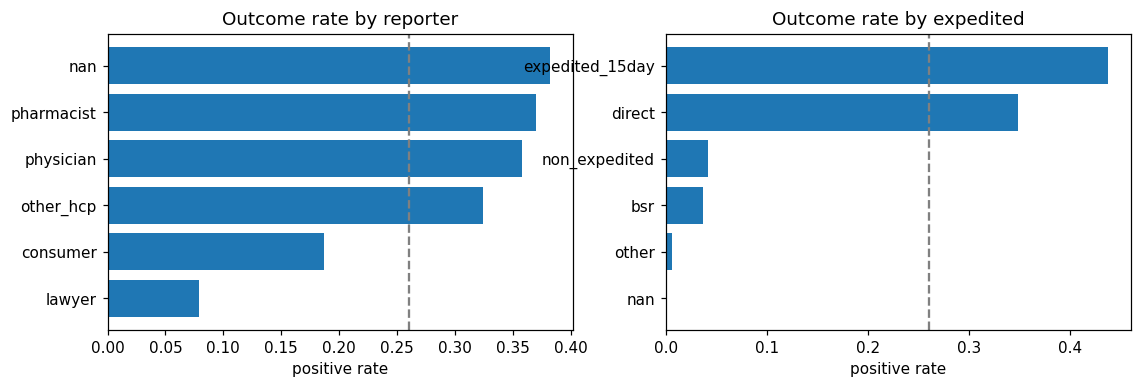

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, col in zip(axes, ["reporter", "expedited"]):
    r = rate_table(reports, col).sort_values("positive_rate")
    ax.barh(r.index.astype(str), r["positive_rate"])
    ax.axvline(BASE_RATE, color="grey", ls="--")
    ax.set_xlabel("positive rate")
    ax.set_title(f"Outcome rate by {col}")
save_fig(fig, "reporter_expedited_vs_target")
plt.show()

### EDA findings:

Base rate: **26.1%** of the 8.38M known-target cases involve hospitalization or death.

| # | Finding | Evidence | Decision (proposed) |
|---|---|---|---|
| 1 | Target is stable over time once the 2021Q4 coding change is handled | 22–30% every quarter, unknown ≤ 4% | One combined target; time split is safe |
| 2 | Death and hospitalization overlap little (143k cases have both) | crosstab, section 2 | Keep the combined target; death-only is a possible extension |
| 3 | Age is strong and non-linear: flat to ~45, then rises to 57% at 95+; infants also high | age plot | Keep `age_years` **and** `age_group` (or a spline); tree models handle it natively |
| 4 | Missingness is predictive: missing age 18% vs. 32% present | section 3 | Add `age_missing`, `sex_missing`, `weight_missing` indicators |
| 5 | Male 32% vs. female 24% | section 3 | Keep `sex` |
| 6 | Polypharmacy: 20% (1 drug) → 50% (21+ drugs) | polypharmacy plot | `log1p(n_drugs)`, `log1p(n_suspect_ingredients)` |
| 7 | Drug identity matters a lot: lift 0.001 (adapalene) to 3.4 (epcoritamab) | section 4 | Top-K ingredient multi-hot; K ≈ 400 covers 80% of mentions, ≈ 1,000 covers 95% |
| 8 | Some top drugs are litigation-driven: ranitidine, oxycodone, hydrocodone ~47% lawyer reports, low rates | section 4 | Keep `reporter` as a feature so the model can separate them |
| 9 | **Reactions leak the target**: `DEATH` 99%, `HOSPITALISATION` 96%, `COMPLETED SUICIDE`, shock, sepsis, arrest… 85%+ | section 5 | **No reaction features in the supervised model.** |
| 10 | **`expedited` nearly encodes the target**: 15-day reports 44%, non-expedited 4% | section 6 | **Exclude** `expedited` (it is assigned *because* the case is serious) |
| 11 | Reporter: HCPs ~35%, consumers 19%, lawyers 8% | section 6 | Keep `reporter` |
| 12 | Study reports 40% vs. spontaneous 22% | section 6 | Keep `report_type` |
| 13 | Geography: US 16% vs. ~40–60% elsewhere (ex-US reports are mostly serious ones forwarded by manufacturers) | section 6 | Keep `is_us` + top-10 `occur_country` |
| 14 | Legacy cases (first received before 2020) 42%: old cases resurface because serious cases get follow-ups | section 6 | Drop from the modeling population; also never use `safetyreportversion` or receipt lag as features (same leak) |
| 15 | Mass reports 6%, 1.4% of cases; the group size is computed over all years | section 6 | Drop from the modeling population (the flag would leak future reports across the split) |

**Next:** notebook 4 applies these decisions: modeling population, time split, features, scaling, baseline models.